# 03.2 — Normalization, Residual Connections and Regularization

Two problems every deep network has: making a *deep* network train at all (normalization, residual connections, initialization),
and stopping it from memorizing the training data (dropout, weight decay, early stopping, augmentation, label smoothing).

## What's in this notebook

- 1\. Two problems: training deep networks, and overfitting
- 2\. Why deep networks are hard to train
- 3\. Batch normalization
- 4\. Layer normalization and RMSNorm
- 5\. Residual connections
- 6\. A 20-layer network: plain vs normalized vs residual
- 7\. Dropout
- 8\. Weight decay
- 9\. Regularization on a small training set
- 10\. Early stopping, data augmentation and label smoothing
- 11\. Trade-offs
- 12\. Interview questions
- 13\. In my own words

In [1]:
import gzip
import hashlib
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

DATA_DIR = Path("../data/fashion-mnist")
URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
MD5 = {"train-images-idx3-ubyte.gz": "8d4fb7e6c68d591d4c3dfef9ec88bf0d", "train-labels-idx1-ubyte.gz": "25c81989df183df01b3e8a0aad5dffbe"}


def load(name: str, offset: int) -> torch.Tensor:
    """Download a FashionMNIST file once, check its MD5, and return its values (see 02.2)."""
    path = DATA_DIR / name
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(URL + name, path)
    assert hashlib.md5(path.read_bytes()).hexdigest() == MD5[name], f"{name}: bad checksum"
    with gzip.open(path) as f:
        return torch.from_numpy(np.frombuffer(f.read(), np.uint8, offset=offset).copy())


X = load("train-images-idx3-ubyte.gz", 16).reshape(-1, 784).float() / 255
y = load("train-labels-idx1-ubyte.gz", 8).long()
X = (X - X[:54_000].mean()) / X[:54_000].std()
X_train, y_train, X_val, y_val = X[:54_000], y[:54_000], X[54_000:], y[54_000:]


def show_error(fn) -> None:
    try:
        fn()
        print("no error")
    except Exception as e:
        print(f"{type(e).__name__}: {str(e).splitlines()[0]}")

# 1. TWO PROBLEMS: TRAINING DEEP NETWORKS, AND OVERFITTING

| Problem | Symptom | Tools (this notebook) |
|---|---|---|
| a deep network won't train | the loss barely moves; early layers get almost no gradient | good initialization, batch / layer normalization, residual connections |
| the network memorizes the training data | training accuracy keeps rising while validation accuracy stalls or falls | more data, data augmentation, dropout, weight decay, early stopping, label smoothing, a smaller model |

The first problem is about **optimization**, the second about **generalization**. Normalization and residual connections are why
networks with hundreds of layers (ResNets, transformers) can be trained at all.

# 2. WHY DEEP NETWORKS ARE HARD TO TRAIN

Backpropagation multiplies one factor per layer (01.1). Over 20 layers, factors a bit below 1 shrink the gradient to almost nothing
(**vanishing gradients**), and factors a bit above 1 blow it up (**exploding gradients**). Activations in the forward pass grow or shrink the same way.

Initialization sets those factors at the start. He initialization (variance 2/fan_in) keeps the signal steady through ReLU layers.
PyTorch's default for `nn.Linear` is smaller than that (uniform in ±1/√fan_in), which is fine for shallow networks but too small for 20 plain ReLU layers.

Below: the gradient reaching each of 20 hidden layers of an untrained network, for one batch.

sigmoid, default init  gradient norm: layer 1 1.0e-17, layer 20 1.0e-01
ReLU, default init     gradient norm: layer 1 8.4e-09, layer 20 5.1e-03
ReLU, He init          gradient norm: layer 1 2.8e+00, layer 20 6.4e+00


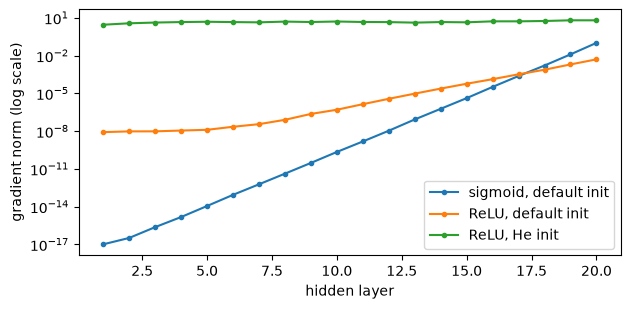

In [2]:
class Block(nn.Module):
    """One hidden layer: optional normalization, linear, activation, optional residual connection."""

    def __init__(self, width: int, activation=nn.ReLU, norm: str | None = None, residual: bool = False):
        super().__init__()
        self.norm = {"batch": nn.BatchNorm1d(width), "layer": nn.LayerNorm(width), None: nn.Identity()}[norm]
        self.linear = nn.Linear(width, width)
        self.activation = activation()
        self.residual = residual

    def forward(self, x):
        h = self.activation(self.linear(self.norm(x)))      # normalize first ("pre-norm"), as modern transformers do
        return x + h if self.residual else h


class DeepMLP(nn.Module):
    def __init__(self, depth: int = 20, width: int = 128, **block_args):
        super().__init__()
        self.inp = nn.Linear(784, width)
        self.blocks = nn.Sequential(*[Block(width, **block_args) for _ in range(depth)])
        self.out = nn.Linear(width, 10)

    def forward(self, x):
        return self.out(self.blocks(self.inp(x)))


def he_init(m: nn.Module) -> None:
    if isinstance(m, nn.Linear):
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
        nn.init.zeros_(m.bias)


def layer_gradients(model: nn.Module) -> list[float]:
    model.zero_grad()
    nn.functional.cross_entropy(model(X_train[:256]), y_train[:256]).backward()
    return [block.linear.weight.grad.norm().item() for block in model.blocks]


setups = {"sigmoid, default init": dict(activation=nn.Sigmoid), "ReLU, default init": {}, "ReLU, He init": "he"}
plt.figure(figsize=(7, 3.2))
for name, args in setups.items():
    torch.manual_seed(0)
    model = DeepMLP() if args == "he" else DeepMLP(**args)
    if args == "he":
        model.apply(he_init)
    grads = layer_gradients(model)
    print(f"{name:<22} gradient norm: layer 1 {grads[0]:.1e}, layer 20 {grads[-1]:.1e}")
    plt.semilogy(range(1, 21), grads, marker=".", label=name)
plt.xlabel("hidden layer")
plt.ylabel("gradient norm (log scale)")
plt.legend()
plt.show()

With sigmoid, the gradient at layer 1 (1e-17) is 16 orders of magnitude smaller than at layer 20 (0.1): the first layers will never learn. ReLU with PyTorch's default initialization still vanishes (8e-9 at layer 1). With He initialization the gradient stays in the same range at every layer (2.8 at layer 1, 6.4 at layer 20).

# 3. BATCH NORMALIZATION

**BatchNorm** normalizes each feature over the current batch, then lets the network rescale it with two learned numbers per feature:

```text
x̂ = (x − batch mean) / √(batch variance + ε)        for each feature
y = γ · x̂ + β                                       γ (scale) and β (shift) are learned
```

- **Training vs eval:** during training it uses the batch's own statistics and updates **running averages** of them (buffers);
  in eval mode it uses those running averages, so a single example gives the same answer whatever else is in the batch.
- **Why it helps:** every layer receives inputs in a stable range, so higher learning rates work, initialization matters less,
  and the noise from batch statistics regularizes a little. (The original "internal covariate shift" explanation is debated; a smoother loss surface is the more accepted one.)
- **Problems:** it depends on the batch, so small batches give noisy statistics and a batch of one fails in training;
  forgetting `model.eval()` changes predictions; and it fits sequences of varying length poorly. Multi-GPU training needs `SyncBatchNorm` to share statistics.

In [3]:
torch.manual_seed(0)
bn = nn.BatchNorm1d(3)
x = torch.randn(64, 3) * torch.tensor([1.0, 10.0, 100.0]) + torch.tensor([0.0, 50.0, -20.0])
out = bn(x)                                                  # training mode

print("input:   mean", x.mean(0).detach().numpy().round(2), " std", x.std(0).detach().numpy().round(2))
print("output:  mean", out.mean(0).detach().numpy().round(2), " std", out.std(0).detach().numpy().round(2))
print("running mean after one batch:", bn.running_mean.numpy().round(2), "(starts at 0, moves 10% towards each batch mean)")
print("learned:", [n for n, _ in bn.named_parameters()], "| buffers:", [n for n, _ in bn.named_buffers()])

show_error(lambda: bn(torch.randn(1, 3)))                     # a batch of one, in training mode
bn.eval()
print("eval mode, a batch of one works:", tuple(bn(torch.randn(1, 3)).shape))

input:   mean [2.000e-02 4.748e+01 6.810e+00]  std [  0.9    8.9  105.02]
output:  mean [-0. -0. -0.]  std [1.01 1.01 1.01]
running mean after one batch: [0.   4.75 0.68] (starts at 0, moves 10% towards each batch mean)
learned: ['weight', 'bias'] | buffers: ['running_mean', 'running_var', 'num_batches_tracked']
ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 3])
eval mode, a batch of one works: (1, 3)


Three features on very different scales all come out with mean 0 and standard deviation 1. In training mode a batch of one fails:
the variance of a single value is undefined. In eval mode the running averages are used, so it works.

# 4. LAYER NORMALIZATION AND RMSNORM

**LayerNorm** normalizes across the features *of each example*, not across the batch. It doesn't depend on the batch size,
behaves the same in training and eval, and works for sequences of any length, which is why every transformer uses it (or RMSNorm).

**RMSNorm** skips the mean subtraction and only divides by the root mean square: `x / √(mean(x²) + ε) · γ`.
It is cheaper and works as well, so LLaMA, Mistral and most recent LLMs use it.

| Norm | Normalizes over | Depends on the batch? | Used in |
|---|---|---|---|
| BatchNorm | each feature, across the batch | yes | CNNs (ResNet) |
| LayerNorm | all features of one example | no | transformers (BERT, GPT-2), RNNs |
| RMSNorm | all features of one example, no mean subtraction | no | modern LLMs (LLaMA, Mistral, Qwen) |
| GroupNorm | groups of channels in one example | no | CNNs with small batches (detection, segmentation) |

**Pre-norm vs post-norm:** the original transformer normalized *after* adding the residual (post-norm), which trains poorly when deep and needs careful warm-up.
Modern models normalize the input of each sub-layer (pre-norm, like `Block` above), which is much more stable.

In [4]:
torch.manual_seed(0)
x = torch.randn(4, 6) * 5 + 3                                # 4 examples, 6 features
ln, rms = nn.LayerNorm(6), nn.RMSNorm(6)

print("LayerNorm per example:  mean", ln(x).mean(1).detach().numpy().round(3), " std", ln(x).std(1, unbiased=False).detach().numpy().round(3))
print("RMSNorm per example:    root mean square", rms(x).pow(2).mean(1).sqrt().detach().numpy().round(3), " mean", rms(x).mean(1).detach().numpy().round(2))
manual = x / torch.sqrt(x.pow(2).mean(1, keepdim=True) + torch.finfo(x.dtype).eps)
print("RMSNorm by hand matches nn.RMSNorm:", torch.allclose(manual, rms(x), atol=1e-6))

LayerNorm per example:  mean [-0.  0.  0. -0.]  std [1. 1. 1. 1.]
RMSNorm per example:    root mean square [1. 1. 1. 1.]  mean [0.42 0.44 0.89 0.32]
RMSNorm by hand matches nn.RMSNorm: True


LayerNorm gives each example mean 0 and standard deviation 1. RMSNorm gives each example a root mean square of 1 but leaves the mean alone; one line of code reproduces it.

# 5. RESIDUAL CONNECTIONS

A **residual (skip) connection** adds a block's input to its output: `y = x + F(x)`.
- The block only has to learn a *correction* to its input. If a layer isn't useful, it can learn F ≈ 0 and pass the input through.
- The gradient of `x + F(x)` with respect to `x` is `1 + F'(x)`: there is always a direct path back to the early layers, so gradients don't vanish.
- ResNet (2015) used them to train 152-layer CNNs; every transformer block has two of them (around attention and around the feed-forward layer).
- On their own, residual sums make activations grow with every block, so they are paired with normalization (pre-norm in transformers, BatchNorm in ResNets).

```text
plain:     x ──► layer ──► layer ──► layer ──► ...
residual:  x ──►(+)──────►(+)──────►(+)──► ...
            └─►F─┘   └─►F─┘   └─►F─┘          F = norm → linear → activation
```

# 6. A 20-LAYER NETWORK: PLAIN VS NORMALIZED VS RESIDUAL

The same 20-layer network in seven versions, each trained for 3 epochs with SGD + momentum (lr 0.01). For each:
the gradient reaching the first hidden layer at the start, and the validation accuracy at the end.

In [5]:
def train_deep(model: nn.Module, epochs: int = 3, lr: float = 0.01, batch: int = 128) -> float:
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    order = torch.Generator().manual_seed(0)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(X_train), generator=order)
        for i in range(len(X_train) // batch):
            idx = perm[i * batch:(i + 1) * batch]
            optimizer.zero_grad()
            nn.functional.cross_entropy(model(X_train[idx]), y_train[idx]).backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        return (model(X_val).argmax(1) == y_val).float().mean().item()


versions = {
    "plain, sigmoid": dict(activation=nn.Sigmoid),
    "plain, ReLU, default init": {},
    "plain, ReLU, He init": dict(init="he"),
    "BatchNorm": dict(norm="batch"),
    "residual, no norm": dict(residual=True),
    "residual + LayerNorm": dict(residual=True, norm="layer"),
    "residual + BatchNorm": dict(residual=True, norm="batch"),
}
for name, args in versions.items():
    torch.manual_seed(0)
    args = dict(args)
    init = args.pop("init", None)
    model = DeepMLP(**args)
    if init == "he":
        model.apply(he_init)
    first_layer_grad = layer_gradients(model)[0]
    print(f"{name:<26} first-layer gradient at start {first_layer_grad:8.1e}   validation accuracy {train_deep(model):.4f}")

plain, sigmoid             first-layer gradient at start  1.0e-17   validation accuracy 0.0942


plain, ReLU, default init  first-layer gradient at start  8.4e-09   validation accuracy 0.0942


plain, ReLU, He init       first-layer gradient at start  2.8e+00   validation accuracy 0.8503


BatchNorm                  first-layer gradient at start  1.4e+01   validation accuracy 0.8517


residual, no norm          first-layer gradient at start  1.7e+01   validation accuracy 0.1050


residual + LayerNorm       first-layer gradient at start  3.2e+00   validation accuracy 0.8713


residual + BatchNorm       first-layer gradient at start  2.3e+00   validation accuracy 0.8750


- **Plain sigmoid and default-init ReLU** stay at chance (0.094), because their early layers get no gradient.
- **He initialization alone** rescues the plain ReLU network (0.850), and **BatchNorm** does the same (0.852).
- **Residual connections without normalization** fail differently: each block adds to the signal, activations and gradients grow, and training blows up (0.105).
- **Residual + LayerNorm (0.871) and residual + BatchNorm (0.875)** are the best. Combining both ideas is exactly the recipe of ResNets and transformers.

# 7. DROPOUT

During training, **dropout** sets each activation to zero with probability `p`, a different random set every step.
- The network can't rely on any single neuron, so it learns redundant, more general features. It is like training many thinned networks and averaging them.
- **Inverted dropout:** the kept values are multiplied by `1 / (1 − p)` during training, so the expected value stays the same and nothing changes at inference.
- At inference (`model.eval()`) dropout is off. Keeping it on and averaging several predictions (**Monte Carlo dropout**) gives a rough uncertainty estimate.
- Typical values: 0.1–0.5 in fully connected layers, 0.1 in transformers (often 0 when pre-training large LLMs on huge data), little or none in CNNs with BatchNorm.

In [6]:
def dropout(x: torch.Tensor, p: float, training: bool = True) -> torch.Tensor:
    if not training or p == 0:
        return x
    keep = (torch.rand_like(x) > p).float()
    return x * keep / (1 - p)


torch.manual_seed(0)
x = torch.ones(100_000)
for name, out in [("by hand", dropout(x, 0.3)), ("nn.Dropout", nn.Dropout(0.3)(x))]:
    print(f"{name:<11} p=0.3: {(out == 0).float().mean():.3f} zeroed, kept values = {out.max():.4f} (1/0.7), mean {out.mean():.3f} (input mean 1.0)")
print("eval mode:", nn.Dropout(0.3).eval()(x[:5]).tolist())

by hand     p=0.3: 0.298 zeroed, kept values = 1.4286 (1/0.7), mean 1.002 (input mean 1.0)
nn.Dropout  p=0.3: 0.301 zeroed, kept values = 1.4286 (1/0.7), mean 0.999 (input mean 1.0)
eval mode: [1.0, 1.0, 1.0, 1.0, 1.0]


About 30% of the values are zeroed and the rest become 1.4286, so the mean stays close to 1.0. In eval mode the input passes through unchanged.

# 8. WEIGHT DECAY

**Weight decay** pulls every weight a little towards zero at each step. Smaller weights give a smoother function that relies less on any single input, which reduces overfitting.
- With SGD it equals L2 regularization (adding `λ·‖w‖²` to the loss). With Adam, use **AdamW** (03.1 section 5).
- **Don't decay biases and normalization weights.** They don't cause overfitting, and shrinking LayerNorm or BatchNorm scales towards zero hurts the model. The usual rule: decay only parameters with 2 or more dimensions (weight matrices and embeddings).
- Typical values: 0.01–0.1 with AdamW (0.1 for LLMs), 1e-4 to 5e-4 with SGD for CNNs.
- L1 regularization pushes weights to exactly zero (sparse). It is rare in deep learning.

In [7]:
def param_groups(model: nn.Module, weight_decay: float) -> list[dict]:
    """Decay weight matrices; leave biases and normalization parameters (1-D) alone."""
    decay = [p for p in model.parameters() if p.ndim >= 2]
    no_decay = [p for p in model.parameters() if p.ndim < 2]
    return [{"params": decay, "weight_decay": weight_decay}, {"params": no_decay, "weight_decay": 0.0}]


model = DeepMLP(depth=2, norm="layer", residual=True)
groups = param_groups(model, weight_decay=0.1)
optimizer = torch.optim.AdamW(groups, lr=1e-3)
print(f"decayed: {len(groups[0]['params'])} tensors ({sum(p.numel() for p in groups[0]['params']):,} numbers) | "
      f"not decayed: {len(groups[1]['params'])} tensors ({sum(p.numel() for p in groups[1]['params']):,} numbers: biases and LayerNorm)")

decayed: 4 tensors (134,400 numbers) | not decayed: 8 tensors (906 numbers: biases and LayerNorm)


# 9. REGULARIZATION ON A SMALL TRAINING SET

With only 2,000 training images and a large network (two layers of 512), the model can memorize the training set.
Five versions, 100 epochs each with AdamW, measured on the 6,000 validation images.

no regularization        final: train acc 1.000, val acc 0.835, val loss 1.308 | best val acc 0.835 (epoch 54) | lowest val loss at epoch 5


dropout 0.5              final: train acc 0.997, val acc 0.831, val loss 1.025 | best val acc 0.841 (epoch 85) | lowest val loss at epoch 10


weight decay 0.1         final: train acc 1.000, val acc 0.836, val loss 1.085 | best val acc 0.838 (epoch 72) | lowest val loss at epoch 5


weight decay 1.0         final: train acc 0.988, val acc 0.824, val loss 0.714 | best val acc 0.838 (epoch 14) | lowest val loss at epoch 5


dropout 0.5 + decay 0.1  final: train acc 0.993, val acc 0.831, val loss 0.855 | best val acc 0.840 (epoch 85) | lowest val loss at epoch 13


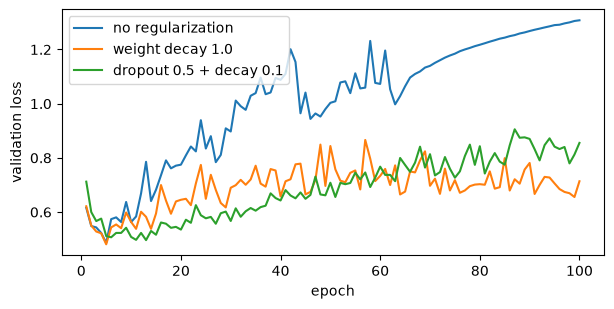

In [8]:
X_small, y_small = X_train[:2000], y_train[:2000]


def big_mlp(p: float = 0.0) -> nn.Module:
    drop = [nn.Dropout(p)] if p else []
    return nn.Sequential(nn.Linear(784, 512), nn.ReLU(), *drop, nn.Linear(512, 512), nn.ReLU(), *drop, nn.Linear(512, 10))


def fit_small(model: nn.Module, weight_decay: float, epochs: int = 100, batch: int = 64) -> list[tuple]:
    optimizer = torch.optim.AdamW(param_groups(model, weight_decay), lr=1e-3)
    order = torch.Generator().manual_seed(0)
    history = []
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(X_small), generator=order)
        for i in range(len(X_small) // batch):
            idx = perm[i * batch:(i + 1) * batch]
            optimizer.zero_grad()
            nn.functional.cross_entropy(model(X_small[idx]), y_small[idx]).backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_logits = model(X_val)
            history.append(((model(X_small).argmax(1) == y_small).float().mean().item(),
                            (val_logits.argmax(1) == y_val).float().mean().item(),
                            nn.functional.cross_entropy(val_logits, y_val).item()))
    return history


runs = {}
for name, p, wd in [("no regularization", 0.0, 0.0), ("dropout 0.5", 0.5, 0.0), ("weight decay 0.1", 0.0, 0.1),
                    ("weight decay 1.0", 0.0, 1.0), ("dropout 0.5 + decay 0.1", 0.5, 0.1)]:
    torch.manual_seed(0)
    h = runs[name] = fit_small(big_mlp(p), wd)
    best = max(range(len(h)), key=lambda i: h[i][1])
    lowest_loss = min(range(len(h)), key=lambda i: h[i][2])
    print(f"{name:<24} final: train acc {h[-1][0]:.3f}, val acc {h[-1][1]:.3f}, val loss {h[-1][2]:.3f} | "
          f"best val acc {h[best][1]:.3f} (epoch {best + 1}) | lowest val loss at epoch {lowest_loss + 1}")

plt.figure(figsize=(7, 3.2))
for name in ["no regularization", "weight decay 1.0", "dropout 0.5 + decay 0.1"]:
    plt.plot(range(1, 101), [h[2] for h in runs[name]], label=name)
plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.legend()
plt.show()

- **Without regularization** the model memorizes the training set (accuracy 1.000) and reaches 0.835 on validation, a 16-point gap. Its validation loss is lowest at epoch 5 and then climbs to 1.31 while validation accuracy stays flat: it becomes ever more confident about the images it gets wrong (Q13).
- **Regularization** improves the best validation accuracy only a little here (up to 0.841), but improves the validation loss a lot (1.31 → 0.86 with dropout + decay, 0.71 with strong decay). The predictions are better calibrated.
- **Too much** weight decay (1.0) starts to underfit: lower training accuracy (0.988) and a lower final validation accuracy (0.824).
- **Early stopping** at the lowest validation loss (epochs 5–13) would keep a well-calibrated model.
- **The biggest lever is more data:** a similar MLP trained on all 54,000 images reached about 0.89 in 02.2.

# 10. EARLY STOPPING, DATA AUGMENTATION AND LABEL SMOOTHING

| Technique | How it regularizes | Where it's used |
|---|---|---|
| **early stopping** | stops before the model starts memorizing; keep the best validation checkpoint (02.3) | almost every training run |
| **data augmentation** | new training examples from label-preserving changes: flips, crops, colour changes for images; noise and speed changes for audio; back-translation or paraphrasing for text | images especially (04.1) |
| **label smoothing** | trains towards 0.9 for the true class (with ε = 0.1) instead of 1.0, so the model stays less overconfident and better calibrated | image classifiers, transformers (ε = 0.1) |
| mixup / CutMix | trains on blends of two images and their labels | image classification |
| stochastic depth | randomly skips whole residual blocks during training | deep ResNets and vision transformers |
| ensembles | average several models | competitions; costly to serve |
| **more data** | the most reliable fix of all | whenever it's possible |

Label smoothing in one example: with plain cross-entropy, a more confident correct prediction is always better. With smoothing, overconfidence costs something:

In [9]:
label = torch.tensor([0])
for gap in [2.0, 5.0, 10.0, 20.0]:
    logits = torch.tensor([[gap, 0.0, 0.0]])                  # the true class leads by `gap`
    plain = nn.functional.cross_entropy(logits, label).item()
    smoothed = nn.functional.cross_entropy(logits, label, label_smoothing=0.1).item()
    print(f"true-class logit ahead by {gap:>4}: probability {torch.softmax(logits, 1)[0, 0]:.5f}  loss {plain:.4f}  with label smoothing 0.1: {smoothed:.4f}")

true-class logit ahead by  2.0: probability 0.78699  loss 0.2395  with label smoothing 0.1: 0.3729
true-class logit ahead by  5.0: probability 0.98670  loss 0.0134  with label smoothing 0.1: 0.3467
true-class logit ahead by 10.0: probability 0.99991  loss 0.0001  with label smoothing 0.1: 0.6668
true-class logit ahead by 20.0: probability 1.00000  loss 0.0000  with label smoothing 0.1: 1.3333


Without smoothing, the loss keeps falling towards 0 as the true class's lead grows (0.0000 at a lead of 20), so the model is always pushed to be more confident. With smoothing 0.1 the target for the true class is 0.933, so the loss is lowest at a lead of about 3.3 (ln 28) and rises again for overconfident predictions (1.33 at a lead of 20).

# 11. TRADE-OFFS

| Decision | Options | What you gain and what you pay | Usual choice |
|---|---|---|---|
| Normalization | BatchNorm / LayerNorm / RMSNorm / GroupNorm | BatchNorm: strong for CNNs, but depends on the batch and differs in train vs eval. LayerNorm: batch-independent, works for sequences. RMSNorm: LayerNorm without the mean, cheaper. GroupNorm: CNNs with small batches | BatchNorm for CNNs, RMSNorm or LayerNorm for transformers |
| Norm placement | post-norm / pre-norm | post-norm: the original transformer, can reach slightly better results but is unstable when deep. Pre-norm: stable, trains deep models easily | pre-norm |
| Going deeper | plain / residual + norm | plain: fails past ~10 layers (section 6). Residual + norm: trains at almost any depth, a little more computation | residual + norm |
| Dropout rate | 0 / 0.1 / 0.5 | higher: stronger regularization, slower training, can underfit. 0: fastest, needs other regularization or lots of data | 0.1 in transformers, up to 0.5 in large dense layers, 0 for LLM pre-training on huge data |
| Weight decay | none / small / large | larger: smaller weights and calmer confidence, but too much underfits (section 9) | AdamW 0.01–0.1, without decay on biases and norms |
| Label smoothing | 0 / 0.1 | 0.1: better calibrated and slightly better accuracy for classifiers; the probabilities no longer reach 1.0 | 0.1 for classifiers; 0 when exact probabilities matter |
| Fighting overfitting | more data / augmentation / regularization / a smaller model | more data is best but costly; augmentation is nearly free for images; regularization is a tuning knob; a smaller model loses capacity | more data or augmentation first, then dropout, weight decay and early stopping |

# 12. INTERVIEW QUESTIONS

### Q1. Your model overfits. What do you do, in 30 seconds?
Confirm it with learning curves (training improving, validation stalling). Then, roughly in order: get more data or use data augmentation;
add regularization (dropout, weight decay with AdamW, label smoothing); use early stopping on a validation set and keep the best checkpoint; and reduce the model size if needed.

### Q2. How does BatchNorm work, and what changes between training and eval?
It normalizes each feature using the batch mean and variance, then applies a learned scale γ and shift β. During training it uses batch statistics
and updates running averages; in eval mode it uses the running averages, so predictions don't depend on the batch. Forgetting `model.eval()` is a classic bug.

### Q3. BatchNorm vs LayerNorm? Why do transformers use LayerNorm?
BatchNorm normalizes each feature across the batch; LayerNorm normalizes across the features of each example. LayerNorm doesn't depend on batch size
or sequence length and behaves the same in training and inference, which suits variable-length sequences and small or uneven batches.

### Q4. What is RMSNorm, and why do LLMs use it?
LayerNorm without the mean subtraction (and usually without the shift β): divide by the root mean square and scale. It's cheaper and works as well, so LLaMA-style models use it.

### Q5. Pre-norm vs post-norm?
Post-norm (the original transformer) applies LayerNorm after adding the residual; pre-norm applies it to the input of each sub-layer, inside the residual branch.
Pre-norm keeps a clean residual path, so deep models train stably with less warm-up; nearly all modern LLMs use it.

### Q6. Why do residual connections help?
The block learns a correction F(x) added to its input, so the identity is easy to learn. The derivative of `x + F(x)` includes 1, giving gradients a direct path
to early layers, which lets very deep networks train. They're paired with normalization so activations don't grow with depth (section 6).

### Q7. How does dropout work, and why scale by 1/(1 − p)?
During training it zeroes each activation with probability p, so the network can't depend on specific neurons, like averaging many thinned networks.
Scaling the kept values by 1/(1 − p) keeps the expected activation the same, so no change is needed at inference, when dropout is turned off.

### Q8. Is weight decay the same as L2 regularization? Why not decay biases and norm parameters?
For SGD they're the same. For Adam they differ, because the L2 gradient gets rescaled per weight; AdamW applies true weight decay.
Biases and normalization scales don't drive overfitting, and decaying norm scales towards zero hurts, so they're usually excluded.

### Q9. What causes vanishing and exploding gradients, and how are they fixed?
Backprop multiplies one factor per layer, so long chains shrink or blow up gradients. Fixes: ReLU-type activations, He or Xavier initialization,
normalization layers, residual connections, gated units in RNNs, and gradient clipping for explosions (03.3).

### Q10. Why can't you train BatchNorm with a batch size of 1?
The batch variance of one value is undefined, and very small batches give noisy statistics that hurt training. Use GroupNorm or LayerNorm, accumulate statistics, or use larger batches.

### Q11. What is label smoothing, and why use it?
It replaces the one-hot target with 1 − ε for the true class and spreads ε over all classes. The model is no longer rewarded for pushing probabilities to exactly 1,
which reduces overconfidence, improves calibration and often accuracy slightly.

### Q12. Why does data augmentation work? What about text?
It creates new, realistic training examples that keep the label, teaching the model which changes don't matter (a flipped shoe is still a shoe).
For text it's harder: back-translation, paraphrasing with an LLM, synonym replacement, or random token masking.

### Q13. Why is validation loss sometimes rising while validation accuracy stays flat?
The model is becoming overconfident: the few examples it gets wrong are predicted with ever higher confidence, so the loss on them grows, while the argmax (accuracy) barely changes.
Regularization, label smoothing and early stopping on the validation loss all help (section 9).

### Q14. Where does dropout go in a transformer, and is it used in LLMs?
After the attention weights, after each sub-layer before the residual add, and on the embeddings, usually at 0.1. Large LLM pre-training on huge datasets often uses no dropout
because a single pass over the data rarely overfits; fine-tuning on small data may add it back.

# 13. IN MY OWN WORDS

Write this from memory, without looking above:

- Why a 20-layer plain network fails, and the three fixes:
- BatchNorm vs LayerNorm vs RMSNorm:
- What a residual connection is, and why it helps:
- How dropout works, including the scaling:
- My checklist when a model overfits: